In [1]:
#load libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import glob
import string
from tabulate import tabulate
import os
from pathlib import Path
import shutil
import geopandas as gpd
from shapely.geometry import Point, Polygon, LineString, box
from tqdm import tqdm
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
import math
import time
from shapely.ops import unary_union
import seaborn as sns
from scipy.spatial import cKDTree
import matplotlib.cm as cm
from matplotlib.patches import Circle
from collections import defaultdict
import pyomo.environ as pyo
import gurobipy as gp
import osmnx as ox, networkx as nx
from osmnx.distance import nearest_nodes
from descartes import PolygonPatch
import requests
import matplotlib.colors as colors
import pickle
from datetime import datetime
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

today = datetime.today().strftime("%Y%m%d")

In [2]:
ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'intermediate_result'
RESULTS_DIR = ROOT_DIR / 'results'

In [3]:
gdf_bogun = gpd.read_file(DATA_DIR / 'gdf_bogun.gpkg', encoding="utf-8-sig")
gdf_bogun.index = gdf_bogun.index.astype(str)
loc_bogun_filtered = pd.read_csv(DATA_DIR / 'loc_bogun_filtered.csv', encoding="utf-8-sig")
loc_bogun_filtered['시군구코드'] = loc_bogun_filtered["EMD_CD"].astype(str).str[:5]

In [4]:
def load_selected_facilities(mode, N, LAMBDA_, T, equity, base_dir = RESULTS_DIR / "optimization_results"):
    tag_map = {"free": "free", "sgg_fixed": "sgg_fixed", "sgg_relaxed": "sgg_relaxed"}
    tag = tag_map[mode]
    tag_1_map = {"base" : "base", "revised_1" : "revised_1", "revised_2" : "revised_2", "revised_3" : "revised_3"}
    tag_1 = tag_1_map[equity]
    pattern = f"{tag}_N{N}_{tag_1}_lambda{LAMBDA_}_T{T}_*.pkl"
    candidates = sorted((Path(base_dir).glob(pattern)),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No file matched: {pattern} in {base_dir}")
    path = candidates[0]
    with open(path, "rb") as f:
        data = pickle.load(f)
    return data, path

In [5]:
from pathlib import Path
import pickle

def load_selected_facilities(mode, LAMBDA_, T, equity, base_dir=RESULTS_DIR / "optimization_results"):
    tag_map = {"free": "free", "sgg_fixed": "sgg_fixed", "sgg_relaxed": "sgg_relaxed"}
    tag = tag_map[mode]
    tag_1_map = {"base": "base", "revised_1": "revised_1", "revised_2": "revised_2", "revised_3": "revised_3"}
    tag_1 = tag_1_map[equity]

    # N 부분을 와일드카드 처리
    if equity == "revised_2":
        pattern = f"{tag}_N*_{tag_1}_T{T}_*.pkl"
    else:
        pattern = f"{tag}_N*_{tag_1}_lambda{LAMBDA_}_T{T}_*.pkl"

    candidates = sorted(Path(base_dir).glob(pattern), key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No file matched: {pattern} in {base_dir}")

    data_by_N = {}
    for path in candidates:
        name = path.stem  # .pkl 제거
        parts = name.split("_")

        if len(parts) < 6:
            continue

        N_part = parts[1]  # "N###"
        if not N_part.startswith("N"):
            continue

        N_value = int(N_part[1:])  # "###"
        with open(path, "rb") as f:
            data_by_N[N_value] = pickle.load(f)

    return data_by_N, candidates


In [6]:
def load_selected_facilities_revised(mode, LAMBDA_, T, timestep, start, equity, base_dir = RESULTS_DIR / "optimization_results"):
    tag_map = {"free": "free", "sgg_fixed": "sgg_fixed", "sgg_relaxed": "sgg_relaxed"}
    tag = tag_map[mode]
    tag_1_map = {"base" : "base", "revised_1" : "revised_1", "revised_2" : "revised_2", "revised_3" : "revised_3"}
    tag_1 = tag_1_map[equity]
    if tag_1 == "revised_2":
        pattern = f"{tag}_{tag_1}_timestep{timestep}_start{start}_T{T}_*.pkl"
    else:
        pattern = f"{tag}_{tag_1}_timestep{timestep}_start{start}_lambda{LAMBDA_}_T{T}_*.pkl"
    candidates = sorted((Path(base_dir).glob(pattern)),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No file matched: {pattern} in {base_dir}")
    path = candidates[0]
    with open(path, "rb") as f:
        data = pickle.load(f)
    return data, path

In [7]:
def load_selected_facilities_greedy(mode, LAMBDA_, T, timestep, start, equity, base_dir = RESULTS_DIR / "optimization_results"):
    tag_map = {"free": "free", "sgg_fixed": "sgg_fixed", "sgg_relaxed": "sgg_relaxed"}
    tag = tag_map[mode]
    tag_1_map = {"base" : "base", "revised_1" : "revised_1", "revised_2" : "revised_2", "revised_3" : "revised_3"}
    tag_1 = tag_1_map[equity]
    pattern = f"{tag}_{tag_1}_timestep{timestep}_start{start}_greedy_iter_lambda{LAMBDA_}_T{T}_*.pkl"
    candidates = sorted((Path(base_dir).glob(pattern)),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No file matched: {pattern} in {base_dir}")
    path = candidates[0]
    with open(path, "rb") as f:
        data = pickle.load(f)
    return data, path

In [8]:
lambda_ = 0.5
mode = "free"
timestep = 7
start = 3
equity = "base"

In [9]:
selected, p = load_selected_facilities_revised(mode, LAMBDA_=lambda_, T=0.5, timestep=timestep, start = start, equity = equity)
selected_static, p_base = load_selected_facilities(mode, LAMBDA_ = lambda_, T = 0.5, equity = equity)
selected_greedy, p_greedy = load_selected_facilities_greedy(mode, LAMBDA_=lambda_, T=0.5, timestep=timestep, start = start, equity=equity)

file_path = DATA_DIR / "end_2026.pkl"
with open(file_path, "rb") as f:
    end_2026 = pickle.load(f)

file_path = DATA_DIR / "end_2027.pkl"
with open(file_path, "rb") as f:
    end_2027 = pickle.load(f)

file_path = DATA_DIR / "end_2028.pkl"
with open(file_path, "rb") as f:
    end_2028 = pickle.load(f)

original_2026 = {key for key in end_2026 if end_2026[key] == 1}
location_2026 = gdf_bogun.loc[gdf_bogun.index.isin(original_2026)]

original_2027 = {key for key in end_2027 if end_2027[key] == 1}
location_2027 = gdf_bogun.loc[gdf_bogun.index.isin(original_2027)]

original_2028 = {key for key in end_2028 if end_2028[key] == 1}
location_2028 = gdf_bogun.loc[gdf_bogun.index.isin(original_2028)]

In [10]:
gdf_bogun_sol = {}
gdf_bogun_sol_static = {}
gdf_bogun_sol_greedy = {}

# dynamic solution
for t in range(timestep + 1):
    gdf_bogun_sol[t] = gdf_bogun.loc[gdf_bogun.index.isin(selected['activated_facilities'][t])]

gdf_bogun_sol_new = {}
for t in range(timestep + 1):
    gdf_bogun_sol_new[t] = gdf_bogun.loc[gdf_bogun.index.isin(selected['selected_facilities'][t])]

# greedy solution
for t in range(timestep + 1):
    gdf_bogun_sol_greedy[t] = gdf_bogun.loc[gdf_bogun.index.isin(selected_greedy['selected_facilities'][t])]

gdf_bogun_sol_greedy_new = {}
for t in range(timestep + 1):
    gdf_bogun_sol_greedy_new[t] = gdf_bogun.loc[gdf_bogun.index.isin(selected_greedy['activated_facilities'][t])]
    
# static solution
to_rename = {} # key를 변경하기 위한 매핑
for key in selected_static.keys():
    for t in selected['activated_facilities'].keys():
        if len(selected['activated_facilities'][t]) == len(selected_static[key]):
            gdf_bogun_sol_static[t] = gdf_bogun.loc[gdf_bogun.index.isin(selected_static[key])]
            to_rename[key] = t
            break
# 키 변경
for old_key, new_key in to_rename.items():
    selected_static[new_key] = selected_static.pop(old_key)

In [11]:
import math
import pandas as pd

# 선택된 보건소에 따른 격자 접근성 변화 결과 산출

def recompute_grid_accessibility(
    selected_facilities,
    grid_to_inst,
    a_dict,
    Cij
):
    selected_set = set(selected_facilities)

    records = []

    for i, inst_dict in grid_to_inst.items():
        a_i = a_dict[i]

        # 선택된 시설 중 격자 i에 영향 주는 후보
        candidates = [
            j for j in inst_dict.keys()
            if j in selected_set
        ]

        chosen_j = None
        z_i = 0.0

        for j in candidates:
            # j보다 가까운 선택 시설이 있으면 탈락
            closer = Cij.get((i, j), [])
            if any(c in selected_set for c in closer):
                continue
            chosen_j = j
            z_i = inst_dict[j]
            break  # 하나만 허용

        p_i = math.sqrt(a_i + z_i)

        records.append({
            "grid_id": i,
            "a_before": a_i,
            "z": z_i,
            "a_after": a_i + z_i,
            "delta": p_i - math.sqrt(a_i),
            "chosen_facility": chosen_j
        })

    return pd.DataFrame(records)

In [12]:
path = Path(DATA_DIR / "Cij.pkl")
with open(path, "rb") as f:
    Cij = pickle.load(f)

path = Path(DATA_DIR / "a_dict.pkl")
with open(path, "rb") as f:
    a_dict = pickle.load(f)

path = Path(DATA_DIR / "grid_to_inst.pkl")
with open(path, "rb") as f:
    grid_to_inst = pickle.load(f)

In [13]:
gdf_grid_pop = pd.read_csv(DATA_DIR / 'gdf_grid_pop.csv')
gdf_emd = pd.read_csv(DATA_DIR / 'gdf_emd.csv')

In [14]:
from shapely import wkt
gdf_grid_pop['grid_centroid'] = gdf_grid_pop['grid_centroid'].apply(wkt.loads)
gdf_grid_pop['geometry'] = gdf_grid_pop['geometry'].apply(wkt.loads)
gdf_grid_pop = gpd.GeoDataFrame(
    gdf_grid_pop,
    geometry="geometry",
    crs="EPSG:5179"
)

gdf_emd['geometry'] = gdf_emd['geometry'].apply(wkt.loads)
gdf_emd = gpd.GeoDataFrame(
    gdf_emd,
    geometry="geometry",
    crs="EPSG:5179"
)   

In [15]:
df_grid={}
gdf_grid_pop.index = gdf_grid_pop.index.astype(str)
for t in range(0, timestep + 1):
    df_grid[t + 2023] = recompute_grid_accessibility(selected['activated_facilities'][t], grid_to_inst, a_dict, Cij)
    df_grid[t + 2023]["grid_id"] = df_grid[t + 2023]["grid_id"].astype(str)
    df_grid[t + 2023] = df_grid[t + 2023].merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how = 'inner')
    df_grid[t + 2023] = df_grid[t + 2023].drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
    df_grid[t + 2023] = gpd.GeoDataFrame(
        df_grid[t + 2023],
        geometry = 'geometry',
        crs = gdf_grid_pop.crs
    )
    df_grid[t + 2023]['vulnerable'] = (df_grid[t + 2023]['a_before'] < 0.5)
    df_grid[t + 2023]['resolved'] = (df_grid[t + 2023]['vulnerable'] & (df_grid[t + 2023]['a_after'] > 0.5))
    df_grid[t + 2023]['improved accessibility'] = df_grid[t + 2023]['adjusted_population'] * df_grid[t + 2023]['delta']

In [16]:
# 비교군 - greedy iteration solution
df_grid_greedy={}
gdf_grid_pop.index = gdf_grid_pop.index.astype(str)
for t in range(0, timestep + 1):
    df_grid_greedy[t + 2023] = recompute_grid_accessibility(selected_greedy['activated_facilities'][t], grid_to_inst, a_dict, Cij)
    df_grid_greedy[t + 2023]["grid_id"] = df_grid_greedy[t + 2023]["grid_id"].astype(str)
    df_grid_greedy[t + 2023] = df_grid_greedy[t + 2023].merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how = 'inner')
    df_grid_greedy[t + 2023] = df_grid_greedy[t + 2023].drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
    df_grid_greedy[t + 2023] = gpd.GeoDataFrame(
        df_grid_greedy[t + 2023],
        geometry = 'geometry',
        crs = gdf_grid_pop.crs
    )
    df_grid_greedy[t + 2023]['vulnerable'] = (df_grid_greedy[t + 2023]['a_before'] < 0.5)
    df_grid_greedy[t + 2023]['resolved'] = (df_grid_greedy[t + 2023]['vulnerable'] & (df_grid_greedy[t + 2023]['a_after'] > 0.5))
    df_grid_greedy[t + 2023]['improved accessibility'] = df_grid_greedy[t + 2023]['adjusted_population'] * df_grid_greedy[t + 2023]['delta']

In [18]:
# 비교군 - 기존 static solution
df_grid_static = {}
for key in selected_static.keys():
    df_grid_static[key + 2023] = recompute_grid_accessibility(selected_static[key], grid_to_inst, a_dict, Cij)
    df_grid_static[key + 2023]["grid_id"] = df_grid_static[key + 2023]["grid_id"].astype(str)
    df_grid_static[key + 2023] = df_grid_static[key + 2023].merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how = 'inner')
    df_grid_static[key + 2023] = df_grid_static[key + 2023].drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
    df_grid_static[key + 2023] = gpd.GeoDataFrame(
        df_grid_static[key + 2023],
        geometry = 'geometry',
        crs = gdf_grid_pop.crs
    )
    df_grid_static[key + 2023]['vulnerable'] = (df_grid_static[key + 2023]['a_before'] < 0.5)
    df_grid_static[key + 2023]['resolved'] = (df_grid_static[key + 2023]['vulnerable'] & (df_grid_static[key + 2023]['a_after'] > 0.5))
    df_grid_static[key + 2023]['improved accessibility'] = df_grid_static[key + 2023]['adjusted_population'] * df_grid_static[key + 2023]['delta']

In [41]:
print(len(set(selected_static[2])  & set(selected_static[3]) & set(selected_static[4]) & set(selected_static[5]) & set(selected_static[6]) & set(selected_static[7])))
print(len(set(selected['activated_facilities'][2])  & set(selected['activated_facilities'][3]) & set(selected['activated_facilities'][4]) & set(selected['activated_facilities'][5]) & set(selected['activated_facilities'][6]) & set(selected['activated_facilities'][7])))

193
69


In [19]:
# timestep dynamics 결과
result_df = []

for t in range(timestep + 1):
    year = t + 2023
    df_year = df_grid[year]

    # 취약격자 해소
    resolved_cnt = df_year.loc[
        (df_year["vulnerable"] == True) &
        (df_year["resolved"] == True)
    ].shape[0]

    # 취약격자 해소 수혜 인구
    resolved_pop = int(np.sum(df_year.loc[
        (df_year["vulnerable"] == True) &
        (df_year["resolved"] == True)
    ]["adjusted_population"]))

    # 취약격자 cover
    covered_cnt = df_year.loc[
        (df_year["vulnerable"] == True) &
        (df_year["z"] > 0.001)
    ].shape[0]

    # 중증 취약격자 해소
    resolved_severe_cnt =  df_year.loc[
        (df_year["a_before"] < 0.3) &
        (df_year["a_after"] > 0.3)
    ].shape[0]

    # 중증 취약격자 해소 수혜 인구
    resolved_severe_pop =  int(np.sum(df_year.loc[
        (df_year["a_before"] < 0.3) &
        (df_year["a_after"] > 0.3)
    ]['adjusted_population']))

    # 우려 취약격자 해소
    resolved_risk_cnt =  df_year.loc[
        (df_year["a_before"] < 0.7) &
        (df_year["a_after"] > 0.7)
    ].shape[0]

    # 우려 취약격자 해소 수혜 인구
    resolved_risk_pop =  int(np.sum(df_year.loc[
        (df_year["a_before"] < 0.7) &
        (df_year["a_after"] > 0.7)
    ]['adjusted_population']))


    accessibility_improve = int((df_year['delta'] * df_year['adjusted_population']).sum())

    result_df.append({
        "연도": year,
        "해소 취약격자 개수": resolved_cnt,
        "해소 취약격자 수혜 인구" : resolved_pop,
        "해소 중증 취약격자 개수": resolved_severe_cnt,
        "해소 중증 취약격자 수혜 인구" : resolved_severe_pop,
        "해소 우려 취약격자 개수": resolved_risk_cnt,
        "해소 우려 취약격자 수혜 인구" : resolved_risk_pop,
        "접근성 상승 취약격자 개수": covered_cnt,
        "인구 고려 접근성 향상" : accessibility_improve
    })

result_df = pd.DataFrame(result_df)
result_df = result_df.sort_values("연도").reset_index(drop=True)
result_df

,연도,해소 취약격자 개수,해소 취약격자 수혜 인구,해소 중증 취약격자 개수,해소 중증 취약격자 수혜 인구,해소 우려 취약격자 개수,해소 우려 취약격자 수혜 인구,접근성 상승 취약격자 개수,인구 고려 접근성 향상
0,2023,2705,63897,1444,33398,4497,115165,3588,56428
1,2024,3721,88517,1897,43199,6626,171997,4889,81930
2,2025,5121,121522,2747,62890,8579,220914,6531,104880
3,2026,7167,164853,4305,94419,10122,256952,8649,116017
4,2027,7816,179477,4531,98209,11353,290371,9394,124428
5,2028,8074,184896,4574,99191,12432,315135,9650,134993
6,2029,7989,183499,4549,98656,12121,309260,9513,131801
7,2030,7919,181168,4536,98626,11671,296505,9431,126921


In [20]:
# greedy solution 결과
result_df_greedy = []

for t in range(timestep + 1):
    year = t + 2023
    df_year_greedy = df_grid_greedy[year]

    # 취약격자 해소
    resolved_cnt = df_year_greedy.loc[
        (df_year_greedy["vulnerable"] == True) &
        (df_year_greedy["resolved"] == True)
    ].shape[0]

    # 취약격자 해소 수혜 인구
    resolved_pop = int(np.sum(df_year_greedy.loc[
        (df_year_greedy["vulnerable"] == True) &
        (df_year_greedy["resolved"] == True)
    ]["adjusted_population"]))

    # 취약격자 cover
    covered_cnt = df_year_greedy.loc[
        (df_year_greedy["vulnerable"] == True) &
        (df_year_greedy["z"] > 0.001)
    ].shape[0]

    # 중증 취약격자 해소
    resolved_severe_cnt =  df_year_greedy.loc[
        (df_year_greedy["a_before"] < 0.3) &
        (df_year_greedy["a_after"] > 0.3)
    ].shape[0]

    # 중증 취약격자 해소 수혜 인구
    resolved_severe_pop =  int(np.sum(df_year_greedy.loc[
        (df_year_greedy["a_before"] < 0.3) &
        (df_year_greedy["a_after"] > 0.3)
    ]['adjusted_population']))

    # 우려 취약격자 해소
    resolved_risk_cnt =  df_year_greedy.loc[
        (df_year_greedy["a_before"] < 0.7) &
        (df_year_greedy["a_after"] > 0.7)
    ].shape[0]

    # 우려 취약격자 해소 수혜 인구
    resolved_risk_pop =  int(np.sum(df_year_greedy.loc[
        (df_year_greedy["a_before"] < 0.7) &
        (df_year_greedy["a_after"] > 0.7)
    ]['adjusted_population']))


    accessibility_improve = int((df_year_greedy['delta'] * df_year_greedy['adjusted_population']).sum())

    result_df_greedy.append({
        "연도": year,
        "해소 취약격자 개수": resolved_cnt,
        "해소 취약격자 수혜 인구" : resolved_pop,
        "해소 중증 취약격자 개수": resolved_severe_cnt,
        "해소 중증 취약격자 수혜 인구" : resolved_severe_pop,
        "해소 우려 취약격자 개수": resolved_risk_cnt,
        "해소 우려 취약격자 수혜 인구" : resolved_risk_pop,
        "접근성 상승 취약격자 개수": covered_cnt,
        "인구 고려 접근성 향상" : accessibility_improve
    })

result_df_greedy = pd.DataFrame(result_df_greedy)
result_df_greedy = result_df_greedy.sort_values("연도").reset_index(drop=True)
result_df_greedy

,연도,해소 취약격자 개수,해소 취약격자 수혜 인구,해소 중증 취약격자 개수,해소 중증 취약격자 수혜 인구,해소 우려 취약격자 개수,해소 우려 취약격자 수혜 인구,접근성 상승 취약격자 개수,인구 고려 접근성 향상
0,2023,2705,63897,1444,33398,4497,115165,3588,56428
1,2024,3721,88517,1897,43199,6626,171997,4889,81930
2,2025,5121,121522,2747,62890,8579,220914,6531,104880
3,2026,7310,167621,4351,95000,10193,258202,8824,117031
4,2027,7915,180857,4554,98461,11559,295739,9493,126201
5,2028,8099,185651,4585,99337,12513,316898,9702,135421
6,2029,7758,179887,4502,97929,11842,302194,9371,130424
7,2030,7840,181188,4505,98239,11527,294354,9395,126483


In [21]:
result_df_base = []

for key in selected_static.keys():
    key = key + 2023
    df_year = df_grid_static[key]

    # 취약격자 해소
    resolved_cnt = df_year.loc[
        (df_year["vulnerable"] == True) &
        (df_year["resolved"] == True)
    ].shape[0]

    # 취약격자 해소 수혜 인구
    resolved_pop = int(np.sum(df_year.loc[
        (df_year["vulnerable"] == True) &
        (df_year["resolved"] == True)
    ]["adjusted_population"]))

    # 취약격자 cover
    covered_cnt = df_year.loc[
        (df_year["vulnerable"] == True) &
        (df_year["z"] > 0.001)
    ].shape[0]

    # 중증 취약격자 해소
    resolved_severe_cnt =  df_year.loc[
        (df_year["a_before"] < 0.3) &
        (df_year["a_after"] > 0.3)
    ].shape[0]

    # 중증 취약격자 해소 수혜 인구
    resolved_severe_pop =  int(np.sum(df_year.loc[
        (df_year["a_before"] < 0.3) &
        (df_year["a_after"] > 0.3)
    ]['adjusted_population']))

    # 우려 취약격자 해소
    resolved_risk_cnt =  df_year.loc[
        (df_year["a_before"] < 0.7) &
        (df_year["a_after"] > 0.7)
    ].shape[0]

    # 우려 취약격자 해소 수혜 인구
    resolved_risk_pop =  int(np.sum(df_year.loc[
        (df_year["a_before"] < 0.7) &
        (df_year["a_after"] > 0.7)
    ]['adjusted_population']))

    accessibility_improve = int((df_year['delta'] * df_year['adjusted_population']).sum())

    result_df_base.append({
        "연도": key,
        "해소 취약격자 개수": resolved_cnt,
        "해소 취약격자 수혜 인구" : resolved_pop,
        "해소 중증 취약격자 개수": resolved_severe_cnt,
        "해소 중증 취약격자 수혜 인구" : resolved_severe_pop,
        "해소 우려 취약격자 개수": resolved_risk_cnt,
        "해소 우려 취약격자 수혜 인구" : resolved_risk_pop,
        "접근성 상승 취약격자 개수": covered_cnt,
        "인구 고려 접근성 향상" : accessibility_improve
    })

result_df_base = pd.DataFrame(result_df_base)
result_df_base = result_df_base.sort_values("연도").reset_index(drop=True)
result_df_base

,연도,해소 취약격자 개수,해소 취약격자 수혜 인구,해소 중증 취약격자 개수,해소 중증 취약격자 수혜 인구,해소 우려 취약격자 개수,해소 우려 취약격자 수혜 인구,접근성 상승 취약격자 개수,인구 고려 접근성 향상
0,2025,8283,189052,4625,100172,14150,349721,9988,169893
1,2026,8243,188525,4607,99746,13723,341952,9912,153492
2,2027,8149,186609,4586,99355,12855,324416,9738,139444
3,2028,8086,185482,4584,99327,12437,315582,9668,135553
4,2029,8062,185087,4582,99314,12149,309659,9646,131968
5,2030,7981,182646,4575,99207,11768,300937,9548,127924


In [22]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch
import numpy as np

In [23]:
# dynamic solution
emd_access = {}
gdf_emd_access = {}
for t in range(timestep + 1):
    emd_access[t] = df_grid[t+2023].groupby("EMD_CD")["delta"].mean().reset_index(name="access_sum")
    gdf_emd_access[t] = gdf_emd.merge(emd_access[t], on="EMD_CD", how = "left").fillna({"access_sum": 0})

# static solution
emd_access_static = {}
gdf_emd_access_static = {}
for key in df_grid_static.keys():
    emd_access_static[key] = df_grid_static[key].groupby("EMD_CD")["delta"].mean().reset_index(name="access_sum")
    gdf_emd_access_static[key] = gdf_emd.merge(emd_access_static[key], on="EMD_CD", how = "left").fillna({"access_sum": 0})

In [24]:
# 시도명 매핑 dict 추가
sido_name = {
    "11": "Seoul",
    "26": "Busan",
    "27": "Daegu",
    "28": "Incheon",
    "29": "Gwangju",
    "30": "Daejeon",
    "31": "Ulsan",
    "36": "Sejong",
    "41": "Gyeonggi",
    "43": "Chungbuk",
    "44": "Chungnam",
    "46": "Jeonnam",
    "47": "Gyeongbuk",
    "48": "Gyeongnam",
    "50": "Jeju",
    "51": "Gangwon", 
    "52": "Jeonbuk"
}

# --- 시도 경계 만들기 ---
gdf_emd["EMD_CD"] = gdf_emd["EMD_CD"].astype(str).str.zfill(8)
gdf_emd["SIDO_CD"] = gdf_emd["EMD_CD"].str[:2]

# 시도 경계 폴리곤 생성
gdf_sido = gdf_emd.dissolve(by="SIDO_CD").reset_index()
gdf_sido["SIDO_NM"] = gdf_sido["SIDO_CD"].map(sido_name)

# gdf_emd_access에도 시도코드 붙이기
for t in range(timestep + 1):
    gdf_emd_access[t]["SIDO_CD"] = gdf_emd_access[t]["EMD_CD"].astype(str).str.zfill(8).str[:2]
    gdf_emd_access[t]["SIDO_NM"] = gdf_emd_access[t]["SIDO_CD"].map(sido_name)
for key in gdf_emd_access_static.keys():
    gdf_emd_access_static[key]["SIDO_CD"] = gdf_emd_access_static[key]["EMD_CD"].astype(str).str.zfill(8).str[:2]
    gdf_emd_access_static[key]["SIDO_NM"] = gdf_emd_access_static[key]["SIDO_CD"].map(sido_name)

In [25]:
# === 도별 보건소 개수 집계 ===
def count_by_sido(bogun_gdf, label):
    tmp = bogun_gdf.copy()
    tmp["SIDO_CD"] = tmp["EMD_CD"].astype(str).str.zfill(8).str[:2]
    out = tmp["SIDO_CD"].value_counts().sort_index().rename(label)
    return out

# dynamic solution 도별 보건소 개수 집계
count_activated = {}
count_activated_sido = pd.DataFrame()
for t in range(timestep + 1):
    count_activated[t] = count_by_sido(gdf_bogun_sol[t], t + 2023)
    count_activated_sido = pd.concat([count_activated_sido, count_activated[t]], axis = 1).fillna(0).astype(int)
count_activated_sido.index = count_activated_sido.index.map(sido_name)

count_new = {}
count_new_sido = pd.DataFrame()
for t in range(timestep + 1):
    count_new[t] = count_by_sido(gdf_bogun_sol_new[t], t + 2023)
    count_new_sido = pd.concat([count_new_sido, count_new[t]], axis = 1).fillna(0).astype(int)
count_new_sido.index = count_new_sido.index.map(sido_name)
print("도별 dynamic solution")
count_activated_sido

도별 dynamic solution


,2023,2024,2025,2026,2027,2028,2029,2030
Daegu,1,3,4,5,4,3,2,3
Incheon,1,5,7,6,6,6,6,6
Sejong,1,1,1,0,0,0,0,0
Gyeonggi,28,36,36,10,6,8,7,7
Chungbuk,28,40,46,26,20,21,19,16
Chungnam,40,59,61,23,7,11,11,10
Jeonnam,40,74,86,53,27,20,17,18
Gyeongbuk,45,78,105,84,74,69,64,57
Gyeongnam,48,70,79,41,28,24,23,20
Jeju,4,5,8,4,3,1,1,1


In [26]:
# static solution 도별 보건소 개수 집계
count_activated_static = {}
count_activated_static_sido = pd.DataFrame()
for key in gdf_bogun_sol_static.keys():
    count_activated_static[key] = count_by_sido(gdf_bogun_sol_static[key], key + 2023)
    count_activated_static_sido = pd.concat([count_activated_static_sido, count_activated_static[key]], axis = 1).fillna(0).astype(int)
count_activated_static_sido.index = count_activated_static_sido.index.map(sido_name)
count_activated_static_sido = count_activated_static_sido.reindex(sorted(count_activated_static_sido.columns, key=int), axis=1)
print("도별 static solution")
count_activated_static_sido

도별 static solution


,2025,2026,2027,2028,2029,2030
Daegu,4,3,3,3,3,3
Incheon,10,6,6,6,6,6
Ulsan,2,2,1,1,1,1
Sejong,2,0,0,0,0,0
Gyeonggi,27,14,8,8,8,8
Chungbuk,49,34,23,20,16,15
Chungnam,60,30,16,13,11,9
Jeonnam,68,37,25,21,17,17
Gyeongbuk,119,87,71,68,65,55
Gyeongnam,80,44,28,25,23,22


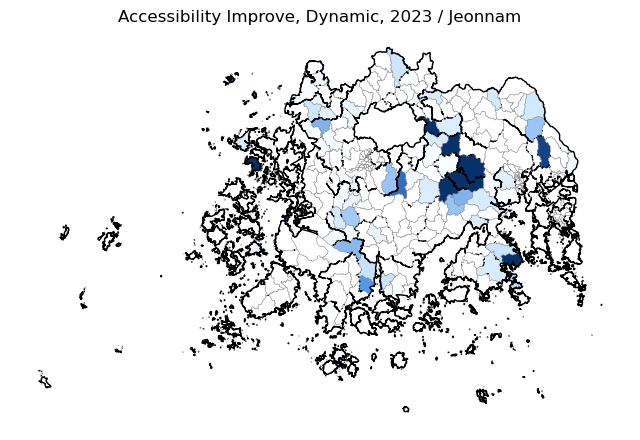

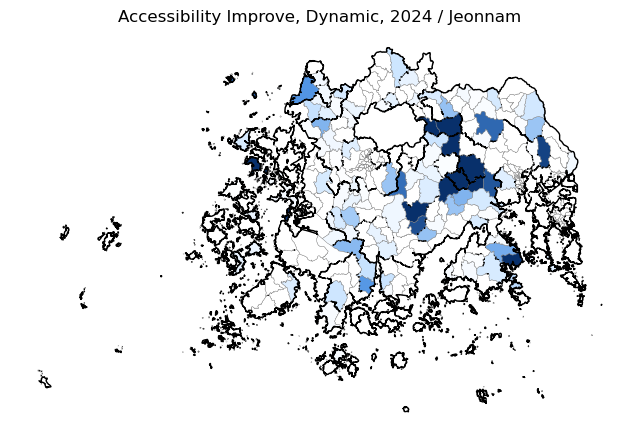

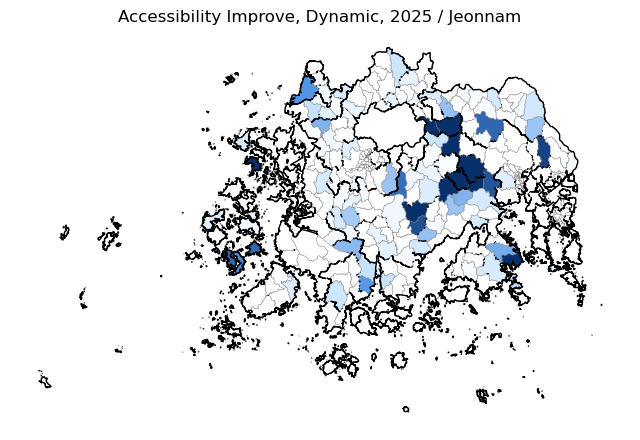

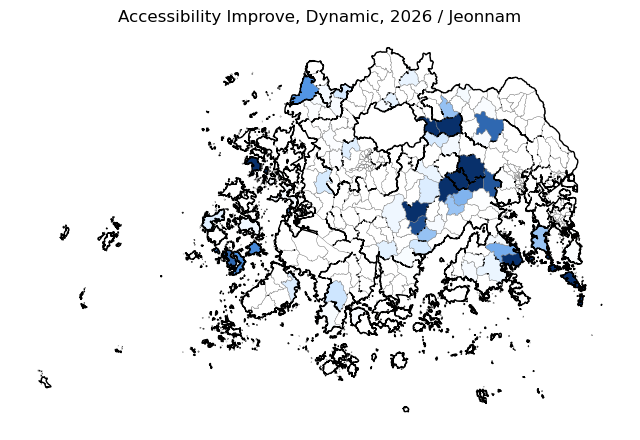

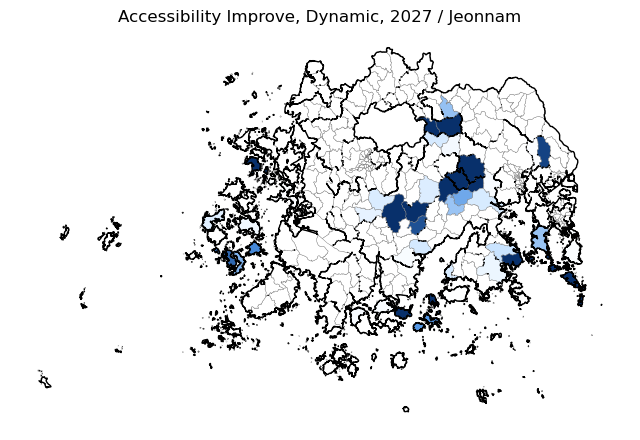

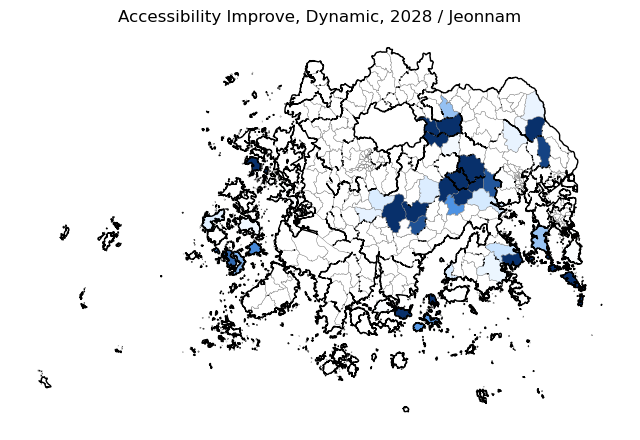

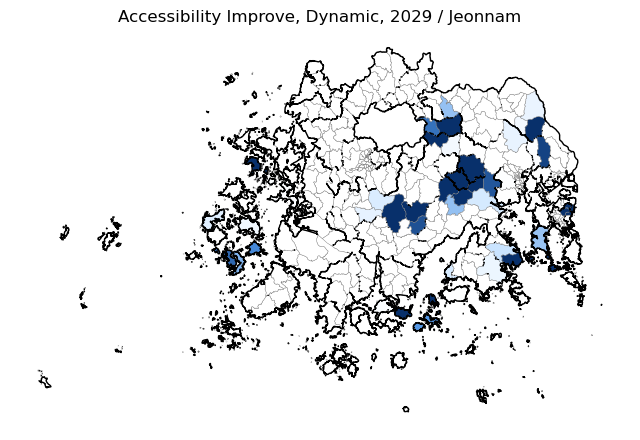

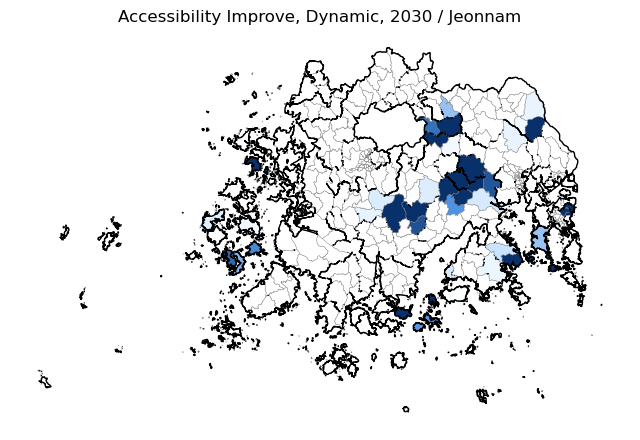

In [27]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "white_to_blue",
    ["#ffffff", "#cce5ff", "#4a90e2", "#08306b"]
)

vmax = 0.117
vmin = 0

sido = "Jeonnam"

for t in range(timestep + 1):
    fig, ax = plt.subplots(figsize=(8, 10))

    # 도 마스크
    mask = gdf_sido[gdf_sido["SIDO_NM"] == sido]

    # 도 내 읍면동만 플롯
    gdf_emd_access[t].loc[
        gdf_emd_access[t]["SIDO_NM"] == sido
    ].plot(
        column="access_sum",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        legend=False,
        edgecolor="gray",
        linewidth=0.3,
        ax=ax
    )

    # 도 경계
    mask.boundary.plot(ax=ax, linewidth=1.0, edgecolor="black")

    ax.set_title(f"Accessibility Improve, Dynamic, {t+2023} / {sido}", fontsize=12)
    ax.axis("off")
    plt.show()

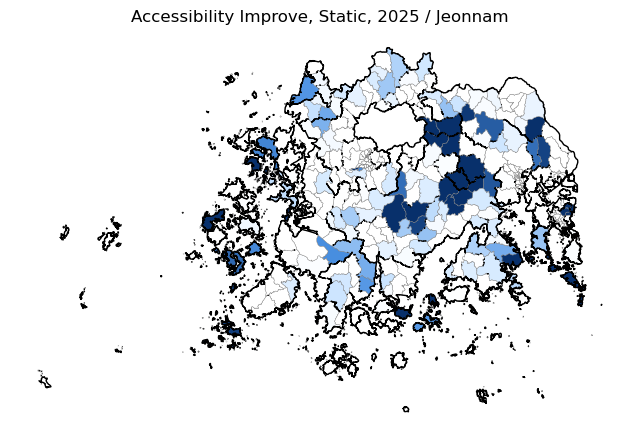

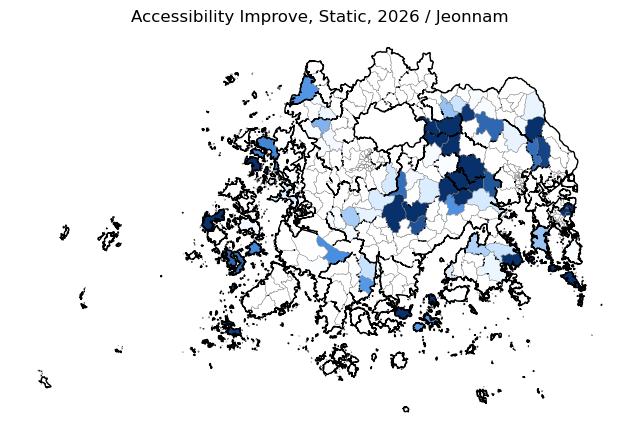

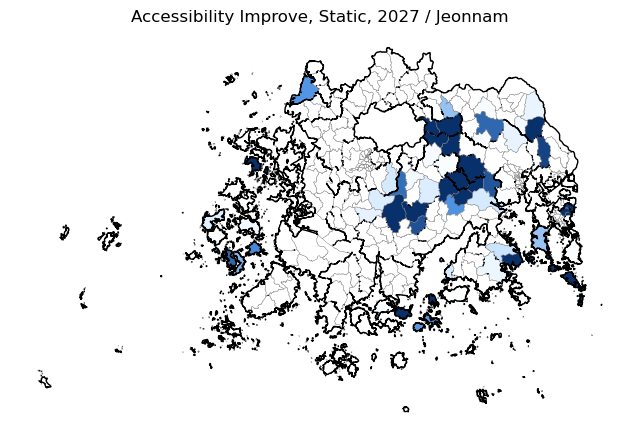

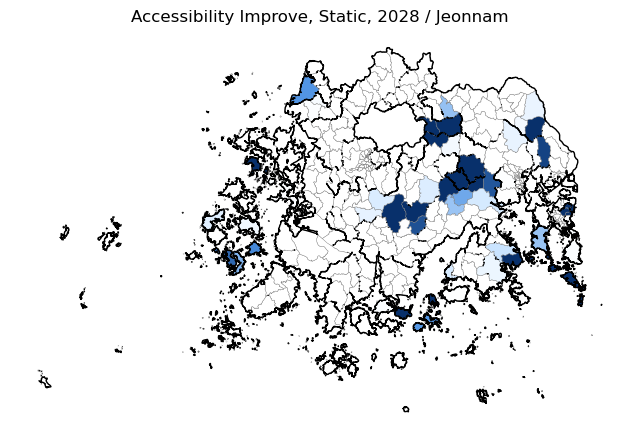

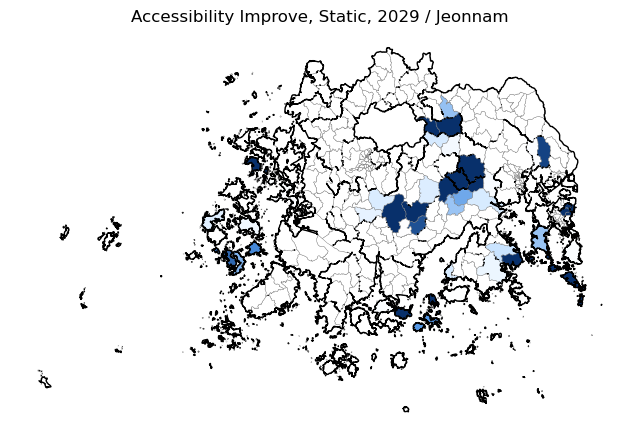

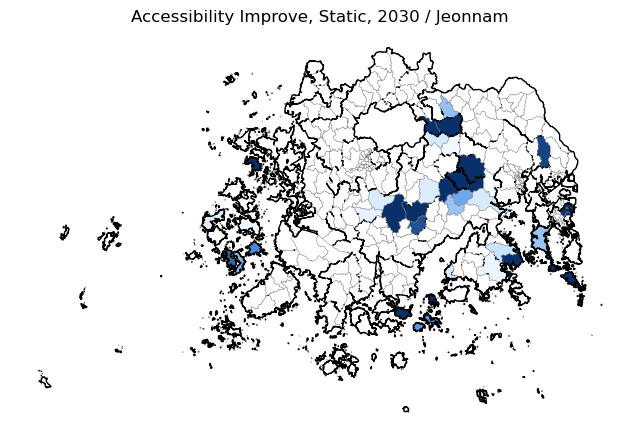

In [28]:
cmap = LinearSegmentedColormap.from_list(
    "white_to_blue",
    ["#ffffff", "#cce5ff", "#4a90e2", "#08306b"]
)

vmax = 0.117
vmin = 0

sido = "Jeonnam"

for t in range(2, timestep + 1):
    fig, ax = plt.subplots(figsize=(8, 10))

    # 도 마스크
    mask = gdf_sido[gdf_sido["SIDO_NM"] == sido]

    # 도 내 읍면동만 플롯
    gdf_emd_access_static[t + 2023].loc[
        gdf_emd_access_static[t + 2023]["SIDO_NM"] == sido
    ].plot(
        column="access_sum",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        legend=False,
        edgecolor="gray",
        linewidth=0.3,
        ax=ax
    )

    # 도 경계
    mask.boundary.plot(ax=ax, linewidth=1.0, edgecolor="black")

    ax.set_title(f"Accessibility Improve, Static, {t+2023} / {sido}", fontsize=12)
    ax.axis("off")
    plt.show()

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\1849883885.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


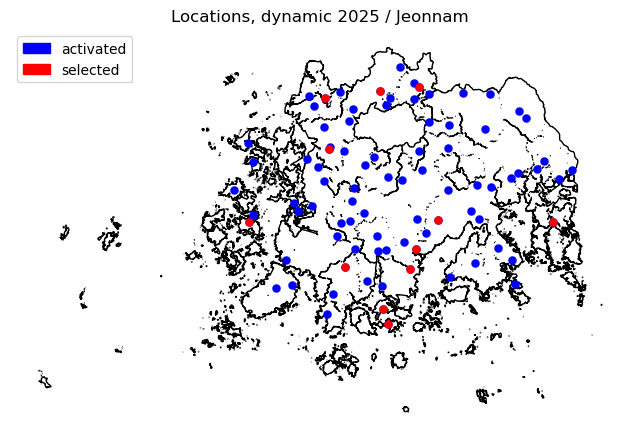

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\1849883885.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


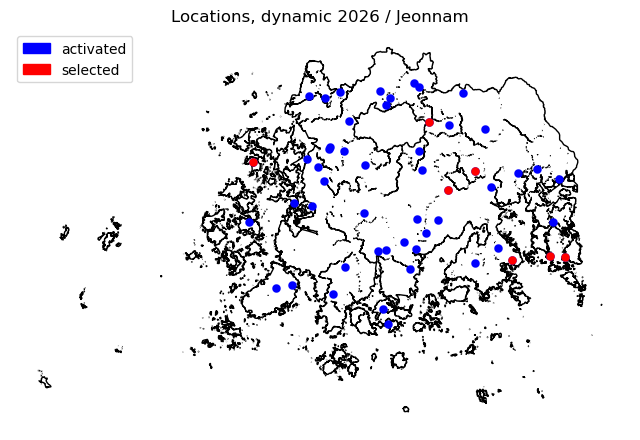

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\1849883885.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


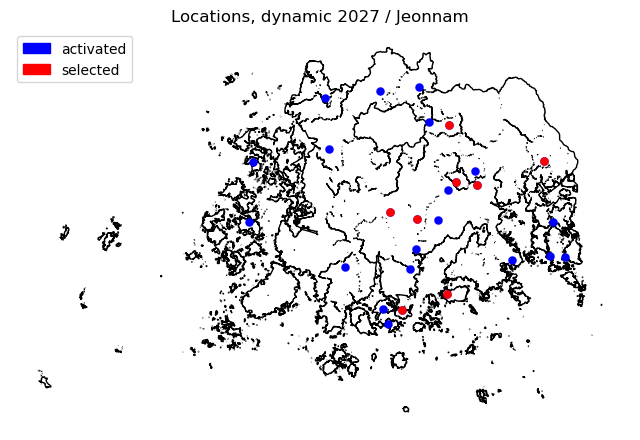

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\1849883885.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


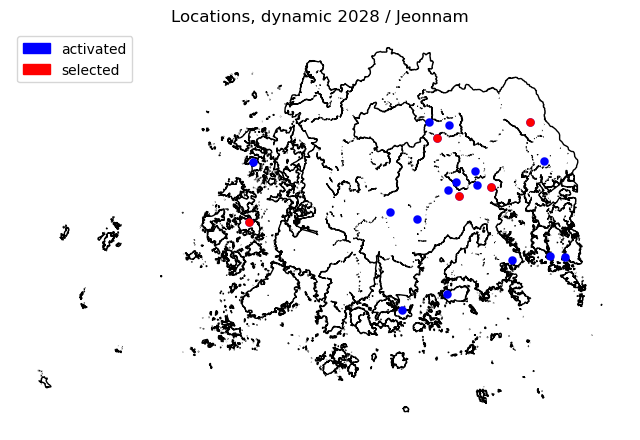

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\1849883885.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


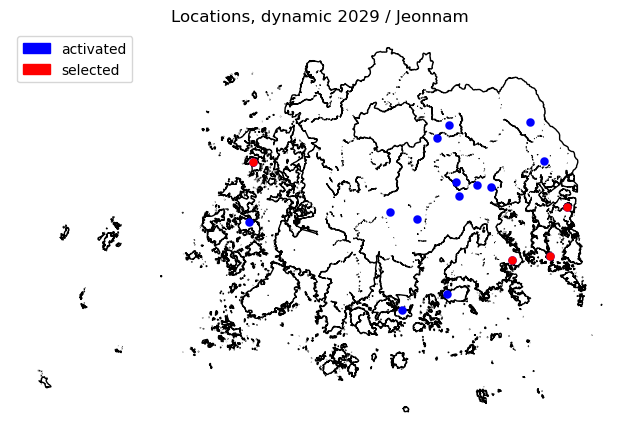

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\1849883885.py:17: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


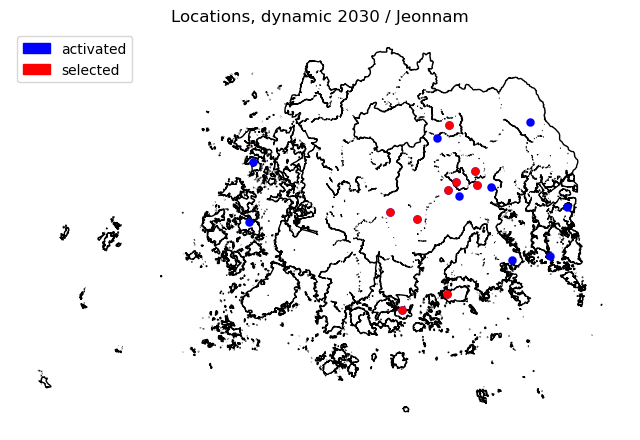

In [29]:
sido = "Jeonnam"

for t in range(2, timestep + 1):
    fig, ax = plt.subplots(figsize=(8, 10))
    mask = gdf_sido[gdf_sido["SIDO_NM"] == sido]

    # 보건소 점: 도 마스크로 clip
    gpd.clip(gdf_bogun_sol[t], mask).plot(
        ax=ax, facecolor="blue", edgecolor="blue", linewidth=0.1, alpha=1.0, zorder=5
    )

    gpd.clip(gdf_bogun_sol_new[t], mask).plot(
        ax=ax, facecolor="red", edgecolor="red", linewidth=0.1, alpha=1.0, zorder=10
    )

    # 읍면동 경계(해당 도만)
    gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(
        ax=ax,
        linewidth=0.2,
        edgecolor="gray",
        alpha=0.4,
        zorder=1
    )

    # 도 경계
    mask.boundary.plot(ax=ax, linewidth=1.0, edgecolor="black")

    legend_elements = [
        Patch(facecolor='blue',  edgecolor='blue', label='activated'),
        Patch(facecolor='red',   edgecolor='red', label='selected'),
    ]

    ax.legend(
        handles=legend_elements,
        loc='upper left',
        fontsize=10,
        title_fontsize=11
    )

    ax.set_title(f"Locations, dynamic {t+2023} / {sido}", fontsize=12)
    ax.axis("off")
    plt.show()

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\509950067.py:26: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


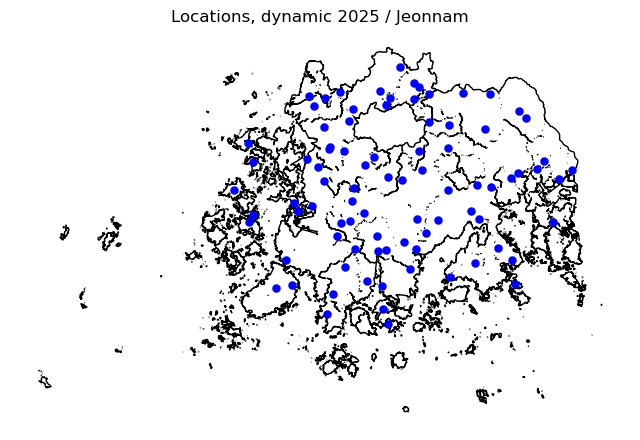

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\509950067.py:26: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


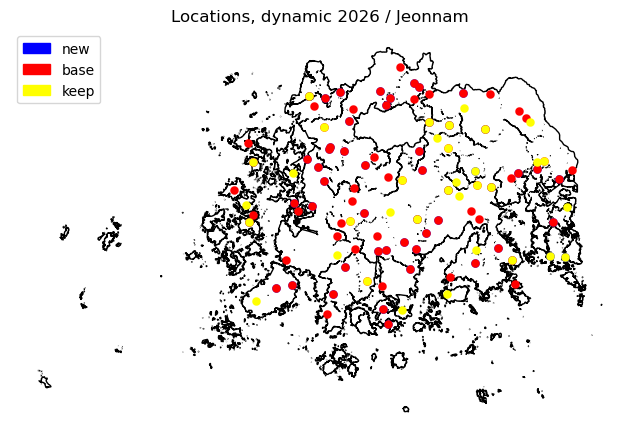

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\509950067.py:26: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


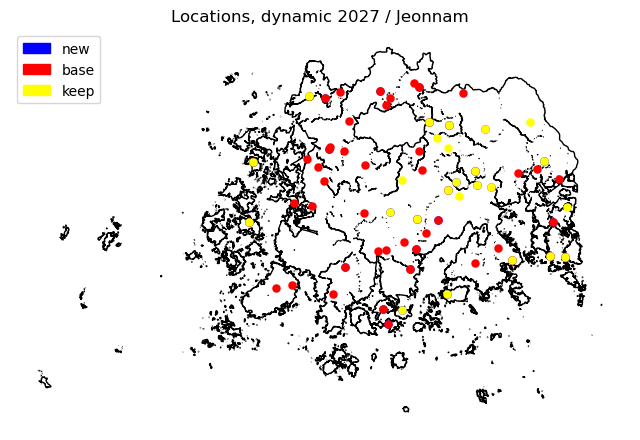

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\509950067.py:26: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


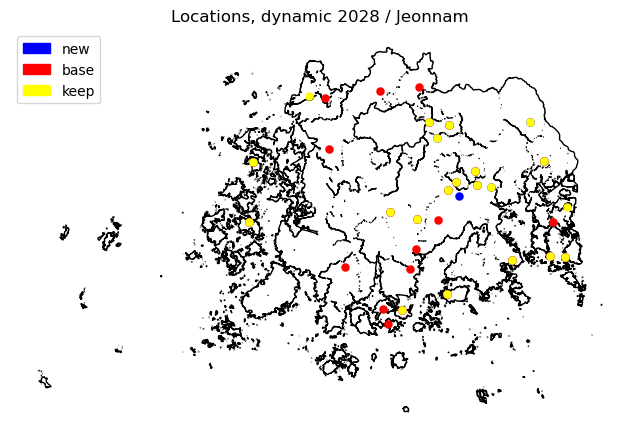

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\509950067.py:26: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


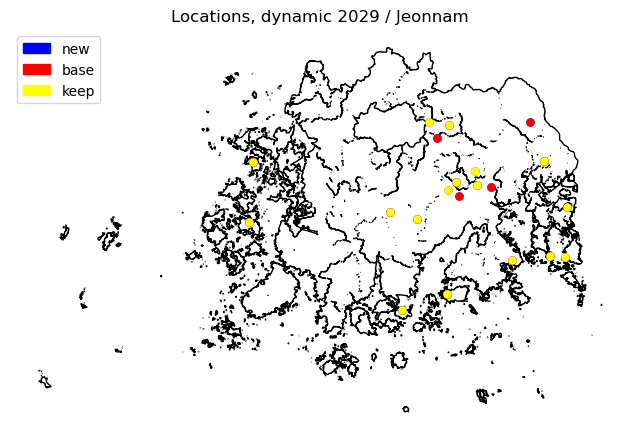

C:\Users\hshoo\AppData\Local\Temp\ipykernel_20908\509950067.py:26: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(


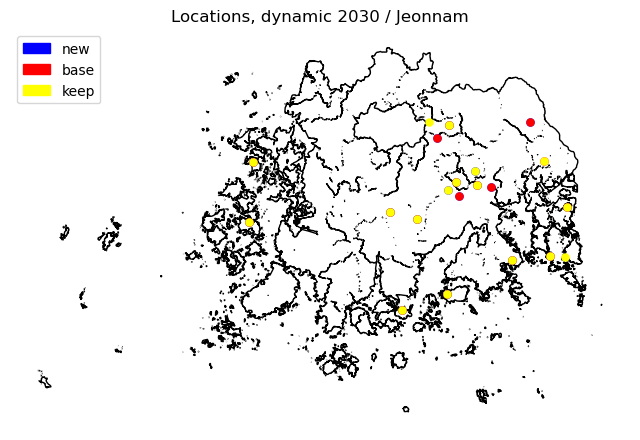

In [30]:
sido = "Jeonnam"

for t in range(2, timestep + 1):
    fig, ax = plt.subplots(figsize=(8, 10))
    mask = gdf_sido[gdf_sido["SIDO_NM"] == sido]

    if t > 2:
        overlap = gdf_bogun.loc[gdf_bogun.index.isin(set(selected_static[t]) & set(selected_static[t - 1]))]

    # 보건소 점: 도 마스크로 clip
    gpd.clip(gdf_bogun_sol[t], mask).plot(
        ax=ax, facecolor="blue", edgecolor="blue", linewidth=0.1, alpha=1.0, zorder=5
    )

    if t > 2:
        gpd.clip(gdf_bogun_sol[t-1], mask).plot(
            ax=ax, facecolor="red", edgecolor="red", linewidth=0.1, alpha=1.0, zorder=5
        )

        gpd.clip(overlap, mask).plot(
            ax=ax, facecolor="yellow", edgecolor="yellow", linewidth=0.1, alpha=1.0, zorder=10
        )


    # 읍면동 경계(해당 도만)
    gdf_emd.loc[gdf_emd["SIDO_CD"] == sido].boundary.plot(
        ax=ax,
        linewidth=0.2,
        edgecolor="gray",
        alpha=0.4,
        zorder=1
    )

    # 도 경계
    mask.boundary.plot(ax=ax, linewidth=1.0, edgecolor="black")

    if t > 2:
        legend_elements = [
            Patch(facecolor='blue',  edgecolor='blue', label='new'),
            Patch(facecolor='red',   edgecolor='red', label='base'),
            Patch(facecolor='yellow',   edgecolor='yellow', label='keep'),
        ]

        ax.legend(
            handles=legend_elements,
            loc='upper left',
            fontsize=10,
            title_fontsize=11
        )

    ax.set_title(f"Locations, dynamic {t+2023} / {sido}", fontsize=12)
    ax.axis("off")
    plt.show()

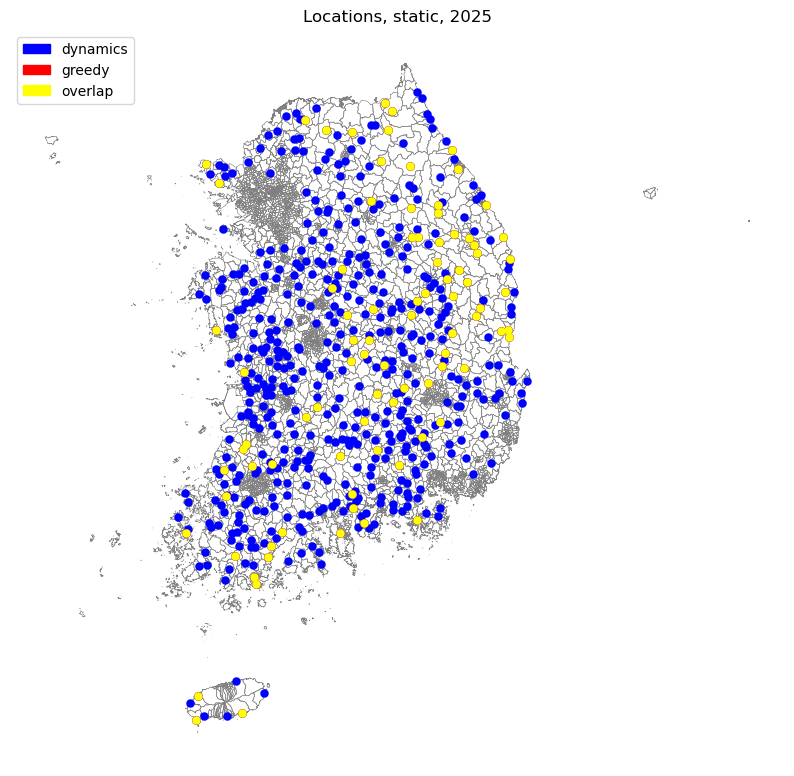

88
88
88


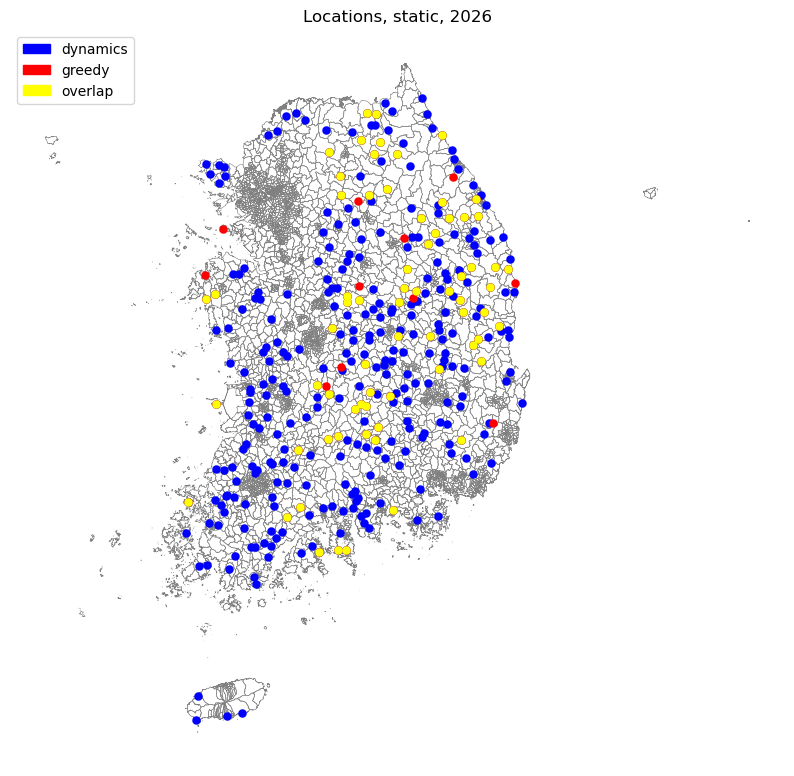

80
80
69


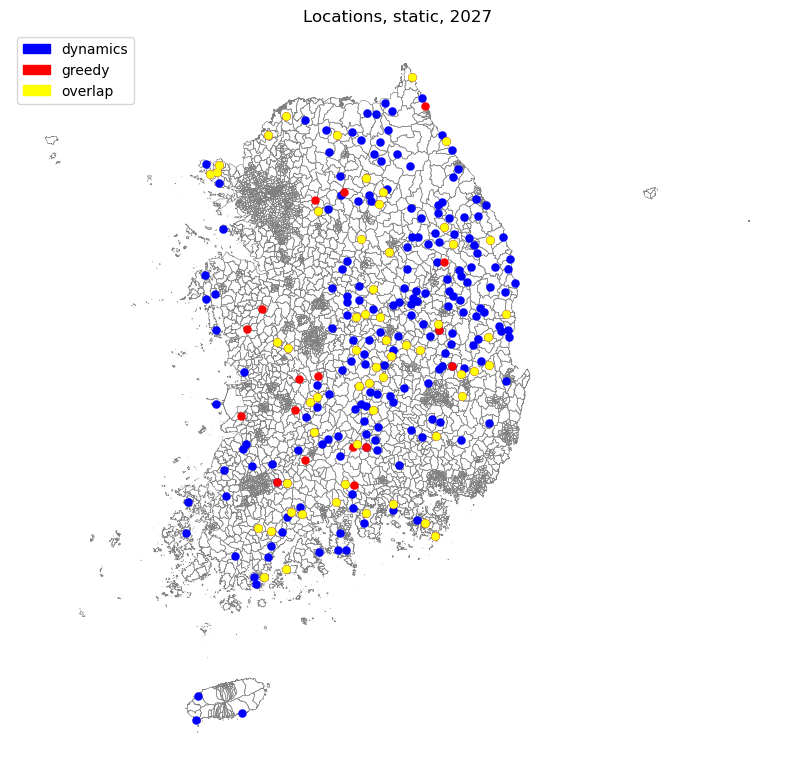

75
75
58


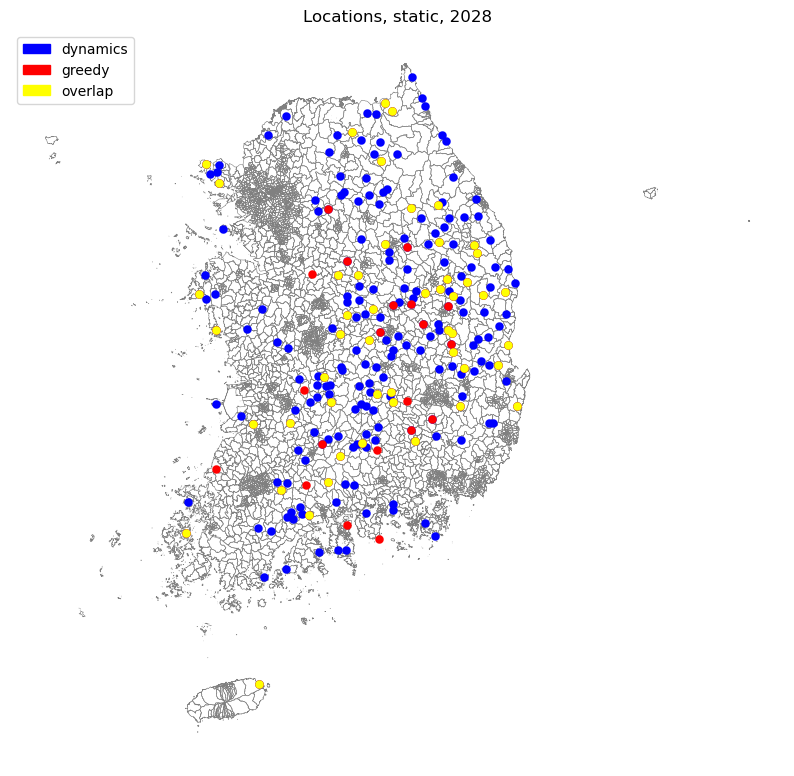

70
70
50


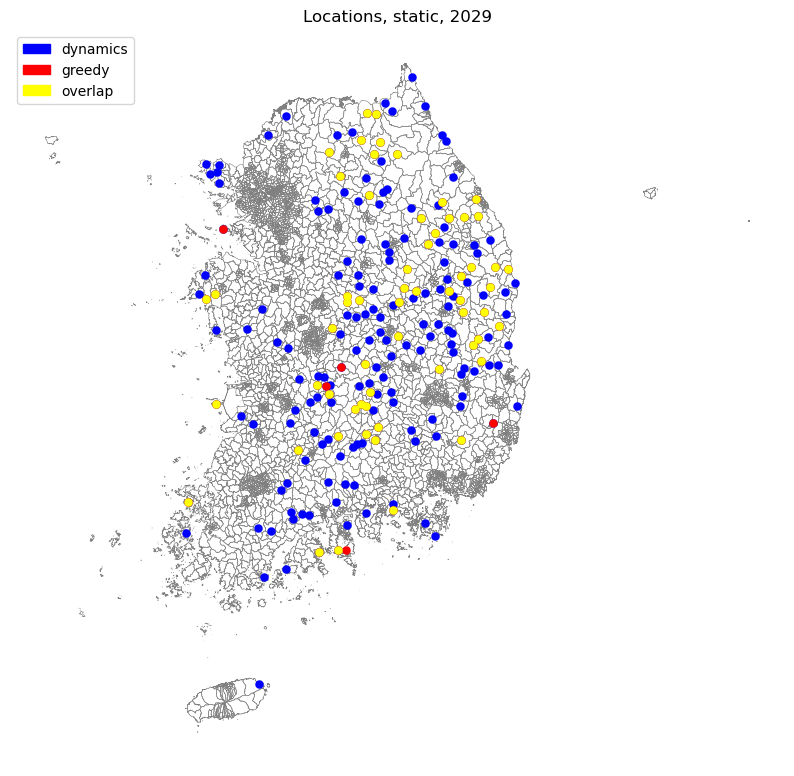

65
65
60


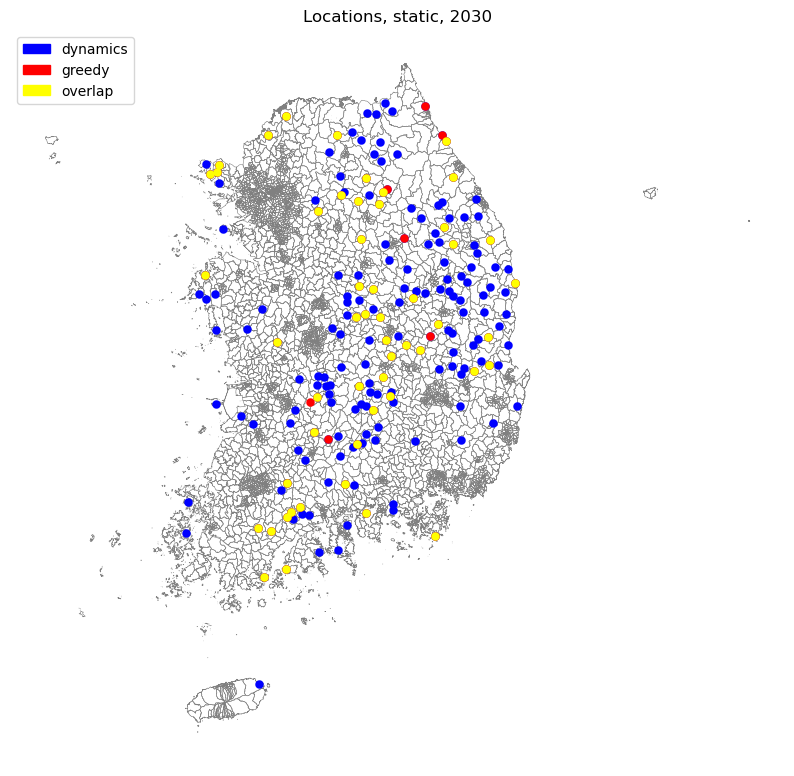

60
60
53


In [31]:
for t in range(2, timestep + 1):
    fig, ax = plt.subplots(figsize=(10, 12))

    overlap = gdf_bogun.loc[gdf_bogun.index.isin(set(selected['selected_facilities'][t]) & set(selected_greedy['selected_facilities'][t]))]

    # 보건소 점: 도 마스크로 clip
    gdf_bogun_sol[t].plot(
        ax=ax, facecolor="blue", edgecolor="blue", linewidth=0.1, alpha=1.0, zorder=5
    )

    gdf_bogun_sol_greedy[t].plot(
        ax=ax, facecolor="red", edgecolor="red", linewidth=0.1, alpha=1.0, zorder=5
    )

    overlap.plot(
        ax=ax, facecolor="yellow", edgecolor="yellow", linewidth=0.1, alpha=1.0, zorder=5
    )


    # 읍면동 경계
    gdf_emd.boundary.plot(
        ax=ax,
        linewidth=0.4,
        edgecolor='gray'
    )

    legend_elements = [
        Patch(facecolor='blue',  edgecolor='blue', label='dynamics'),
        Patch(facecolor='red',   edgecolor='red', label='greedy'),
        Patch(facecolor='yellow',   edgecolor='yellow', label='overlap'),
    ]

    ax.legend(
        handles=legend_elements,
        loc='upper left',
        fontsize=10,
        title_fontsize=11
    )

    ax.set_title(f"Locations, static, {t+2023}", fontsize=12)
    ax.axis("off")
    plt.show()

    print(len(selected_greedy['selected_facilities'][t]))
    print(len(selected['selected_facilities'][t]))
    print(len(overlap))

In [32]:
new_static = {}
new_static[3] = set(selected_static[2]) - set(selected_static[3])
new_static[4] = set(selected_static[2]) - set(selected_static[4])
print(len(set(selected_static[3]) | set(selected_static[4]) | set(selected_static[5]) | set(selected_static[6]) | set(selected_static[7])))
print(len(set(selected_greedy['activated_facilities'][2]) & set(selected_greedy['activated_facilities'][3]) & set(selected_greedy['activated_facilities'][4]) & set(selected_greedy['activated_facilities'][5]) & set(selected_greedy['activated_facilities'][6]) & set(selected_greedy['activated_facilities'][7])))
print(len(set(selected['activated_facilities'][3]) | set(selected['activated_facilities'][4]) | set(selected['activated_facilities'][5]) | set(selected['activated_facilities'][6]) | set(selected['activated_facilities'][7])))

342
69
431


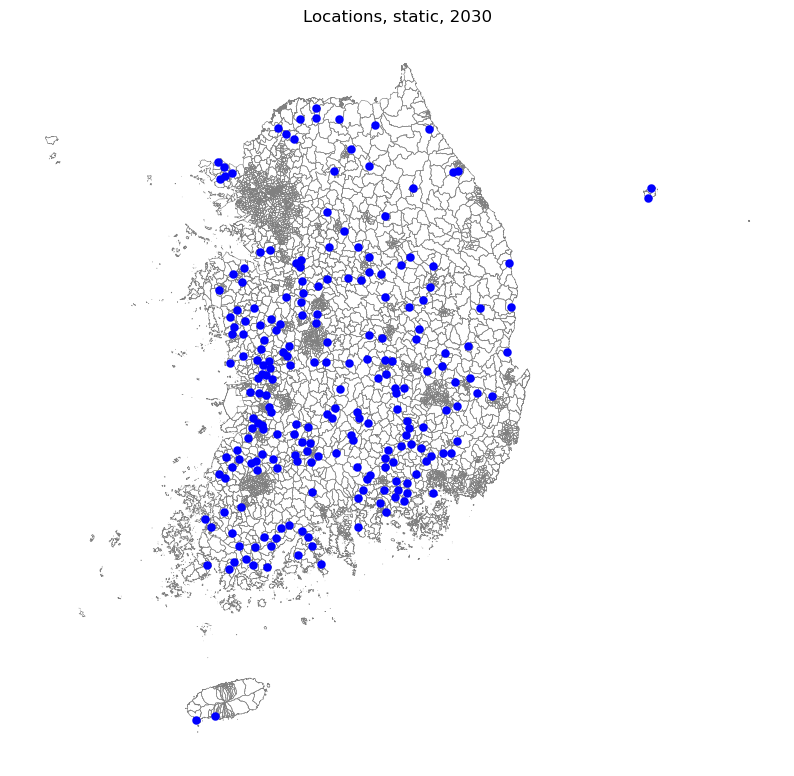

218


In [33]:
fig, ax = plt.subplots(figsize=(10, 12))

new_static = gdf_bogun.loc[gdf_bogun.index.isin(set(selected_static[2]) - set(selected_static[3]))]

# 보건소 점: 도 마스크로 clip
new_static.plot(
    ax=ax, facecolor="blue", edgecolor="blue", linewidth=0.1, alpha=1.0, zorder=5
)


# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)


ax.set_title(f"Locations, static, {t+2023}", fontsize=12)
ax.axis("off")
plt.show()
print(len(new_static))

In [34]:
# 정책적 부담 분석 (timestep을 고려하지 않고 최적화했을 때 공보의의 이동)
len(original_2026)

293

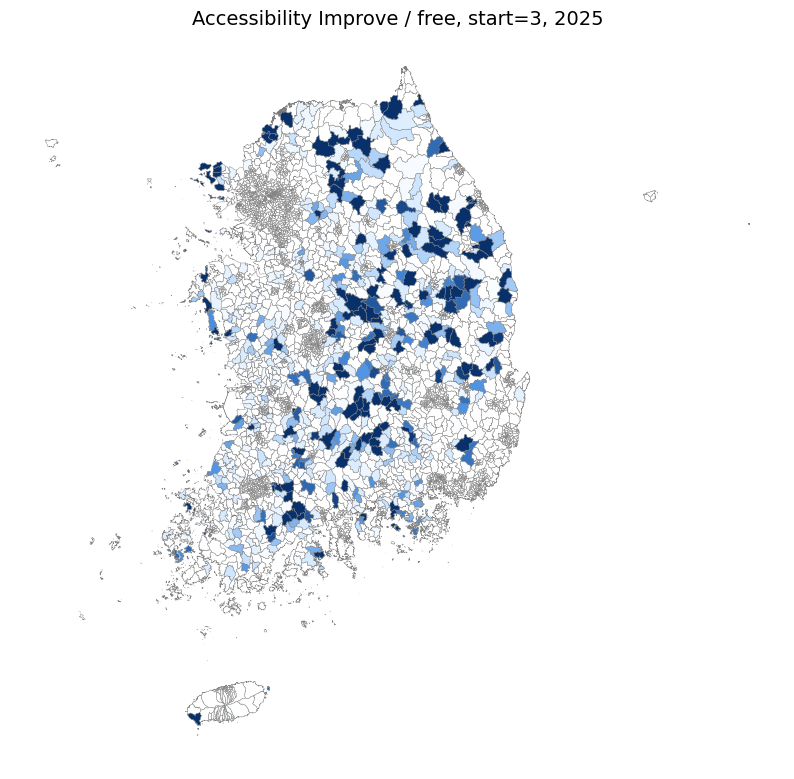

In [35]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "white_to_blue",
    ["#ffffff", "#cce5ff", "#4a90e2", "#08306b"]
)

fig, ax = plt.subplots(figsize=(10, 12))

# vmax = max(np.abs(gdf_emd_access[y]["access_sum"]).quantile(0.95) for y in range(timestep + 1))
vmax = 0.117
vmin = 0

year = 2
gdf_emd_access[year].plot(
    column="access_sum",
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    legend=False,
    # legend_kwds={'shrink' : 0.6},
    edgecolor="gray",
    linewidth=0.3,
    ax=ax
)

ax.set_title(f"Accessibility Improve / {mode}, start={start}, {year + 2023}", fontsize=14)
ax.axis("off")
plt.show()

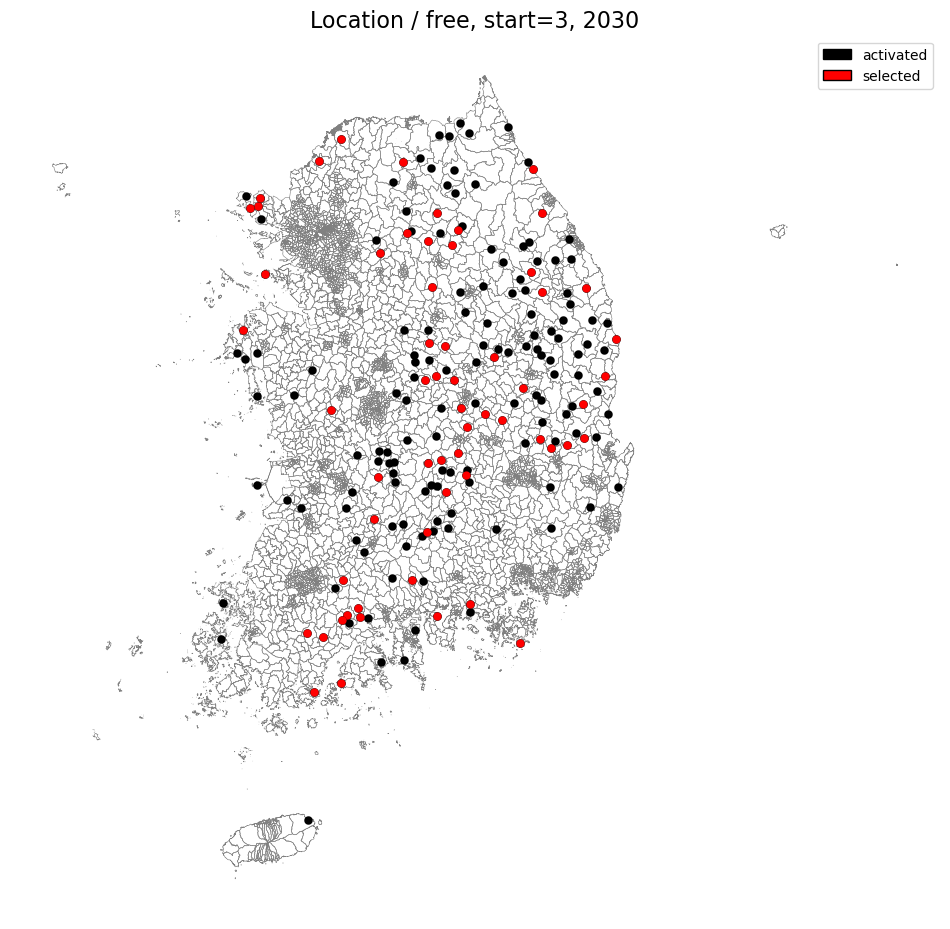

In [36]:
fig, ax = plt.subplots(figsize=(12, 14))

# 보건소
t=7

gdf_bogun_sol[t].plot(
    ax=ax,
    facecolor='black',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 5
)

gdf_bogun_sol_new[t].plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 10 
)

legend_elements = [
    Patch(facecolor='black',  edgecolor='black', label='activated'),
    Patch(facecolor='red',   edgecolor='black', label='selected'),
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=10,
    title_fontsize=11
)

# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

ax.set_title(f"Location / {mode}, start={start}, {t + 2023}", fontsize=16)
ax.axis('off')

plt.show()